In [1]:
from pathlib import Path
from collections import Counter

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)

OpenCV: 4.12.0
NumPy: 1.26.4


In [2]:
# %pip install opencv-python numpy pandas matplotlib scikit-learn

## 01. Data Verify

In [3]:
DATA_DIR = Path("../data/FIRE-SMOKE-DATASET/Train/").resolve()

print("Dataset path:", DATA_DIR)
print("Exists:", DATA_DIR.exists())

if DATA_DIR.exists():
    for item in sorted(DATA_DIR.iterdir()):
        print(item.name, "DIR" if item.is_dir() else "FILE")

Dataset path: /Users/sreeramc/Desktop/UC_Berkeley/281/Project_repo/MIDS-281-project/data/FIRE-SMOKE-DATASET/Train
Exists: True
Fire DIR
Neutral DIR
Smoke DIR


In [4]:
classes = ["Fire", "Smoke", "Neutral"]
extensions = {".jpg", ".jpeg", ".png"}

image_paths = {}

for cls in classes:
    folder = DATA_DIR / cls

    if not folder.exists():
        print(f"Missing class folder: {folder}")
        continue

    paths = sorted(
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in extensions
    )

    image_paths[cls] = paths
    print(f"{cls}: {len(paths)} images")

Fire: 900 images
Smoke: 900 images
Neutral: 900 images


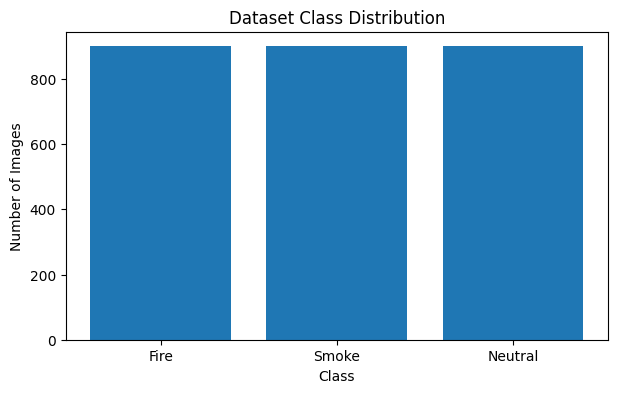

In [5]:
 counts = {
    cls: len(paths)
    for cls, paths in image_paths.items()
}

plt.figure(figsize=(7, 4))
plt.bar(counts.keys(), counts.values())
plt.title("Dataset Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.show()

### Observation:
- Based on the observed data for the three class we find that the classes are balanced for Fire, Smoke and Neutral classes
- Fire dataset is 904 images, Smoke is 907 images and Neutral is 900 images in the training dataset

## 02. Display the images

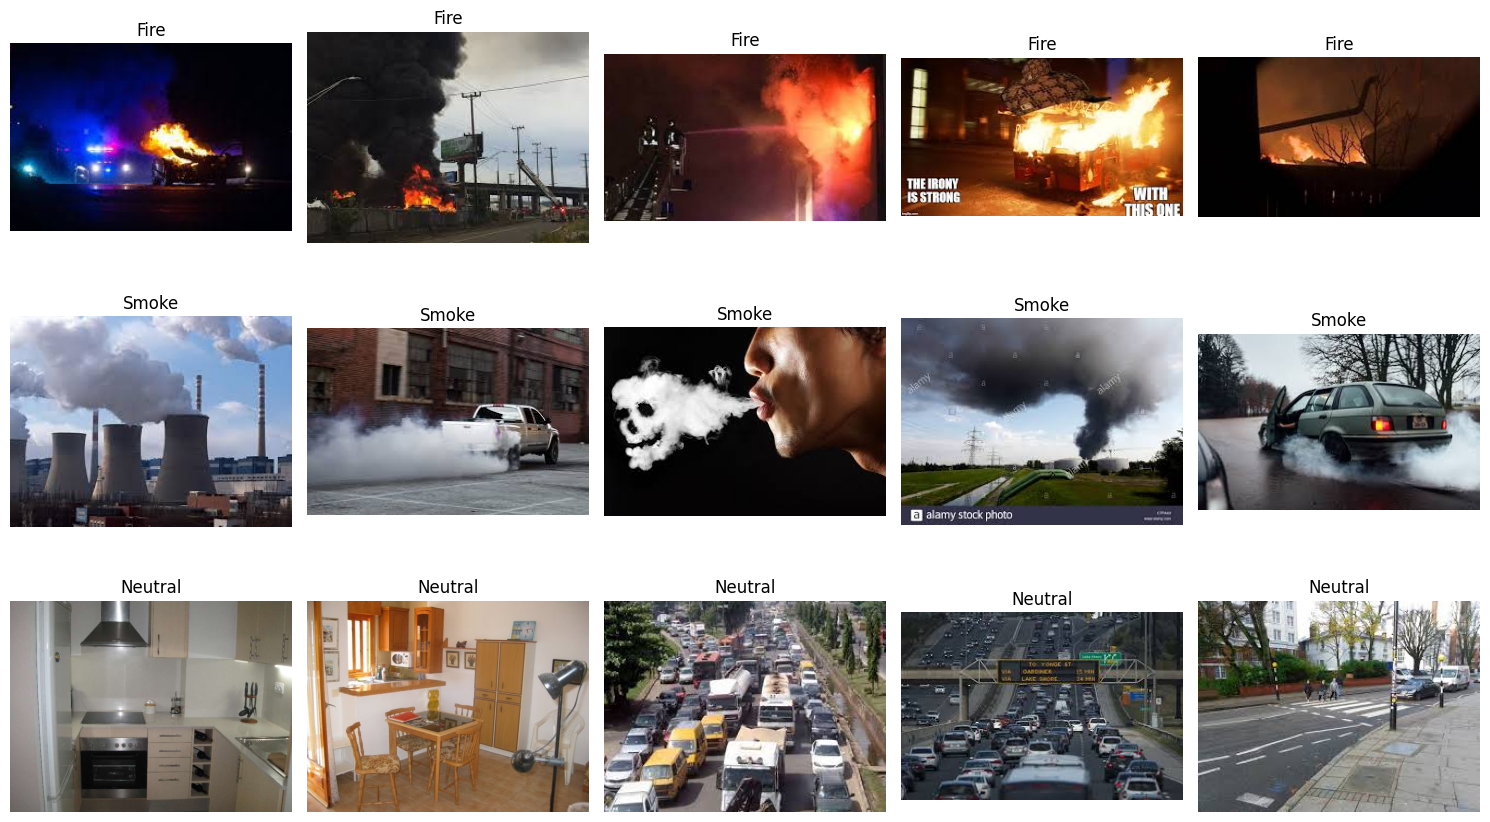

In [6]:
fig, axes = plt.subplots(3, 5, figsize=(15, 9))

for row, cls in enumerate(classes):
    paths = image_paths.get(cls, [])

    for col in range(5):
        ax = axes[row, col]
        ax.axis("off")

        if col >= len(paths):
            continue

        img = cv2.imread(str(paths[col]))

        if img is None:
            continue

        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        ax.imshow(img)
        ax.set_title(cls)

plt.tight_layout()
plt.show()

### Observation:
- The observed dataset for the fire has both fire and smoke together
- The Smoke datasets are more common in gray/white combination and it is more than common smoke of fire
- The neutral scenarios have organge patterns that might confuse the classifier 

## 03. Inspect Images

In [7]:
records = []
bad_files = []

for cls, paths in image_paths.items():
    for path in paths:
        img = cv2.imread(str(path))

        if img is None:
            bad_files.append(str(path))
            continue

        height, width = img.shape[:2]

        records.append({
            "path": str(path),
            "class": cls,
            "width": width,
            "height": height,
            "aspect_ratio": width / height
        })

df = pd.DataFrame(records)

print(df.groupby("class")[["width", "height"]].describe())
print("Unreadable images:", len(bad_files))

         width                                                               \
         count        mean         std    min     25%    50%    75%     max   
class                                                                         
Fire     900.0  274.733333   30.763152  168.0  259.75  275.0  299.0   429.0   
Neutral  900.0  532.253333  418.034287  176.0  275.00  400.0  640.0  3072.0   
Smoke    900.0  270.390000   34.014917   96.0  259.00  275.0  299.0   427.0   

        height                                                               
         count        mean         std    min     25%    50%    75%     max  
class                                                                        
Fire     900.0  185.125556   25.677187  108.0  168.00  183.0  193.0   300.0  
Neutral  900.0  416.972222  324.276905  145.0  255.75  333.0  500.0  2304.0  
Smoke    900.0  189.066667   27.780724  118.0  168.00  183.0  194.0   307.0  
Unreadable images: 0


## 04. Resize the images and store it

In [8]:
def resize_with_padding(img, target_size=(224, 224)):
    target_w, target_h = target_size

    h, w = img.shape[:2]

    scale = min(target_w / w, target_h / h)

    new_w = max(1, int(round(w * scale)))
    new_h = max(1, int(round(h * scale)))

    resized = cv2.resize(
        img,
        (new_w, new_h),
        interpolation=cv2.INTER_AREA if scale < 1 else cv2.INTER_LINEAR
    )

    canvas = np.zeros((target_h, target_w, 3), dtype=np.uint8)

    x = (target_w - new_w) // 2
    y = (target_h - new_h) // 2

    canvas[y:y+new_h, x:x+new_w] = resized

    return canvas

In [9]:
X = []
y = []

for label, cls in enumerate(classes):
    for path in image_paths[cls]:

        img = cv2.imread(str(path))

        if img is None:
            continue

        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        img = resize_with_padding(img)

        X.append(img)
        y.append(label)

X = np.array(X, dtype=np.uint8)
y = np.array(y)

print("Image array:", X.shape)
print("Labels:", y.shape)

Image array: (2700, 224, 224, 3)
Labels: (2700,)


In [10]:
# Pick the first fire image
image_path = image_paths["Fire"][0]

# Read original image
img = cv2.imread(str(image_path))
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Resize using our existing function
resized = resize_with_padding(img_rgb, (224, 224))

# Create output directory
output_dir = Path("../outputs/resized_images")
output_dir.mkdir(parents=True, exist_ok=True)

# Save resized image
save_path = output_dir / "fire_resized.png"

cv2.imwrite(
    str(save_path),
    cv2.cvtColor(resized, cv2.COLOR_RGB2BGR)
)

print("Saved image:", save_path.resolve())
print("Original shape:", img_rgb.shape)
print("Resized shape:", resized.shape)

Saved image: /Users/sreeramc/Desktop/UC_Berkeley/281/Project_repo/MIDS-281-project/outputs/resized_images/fire_resized.png
Original shape: (160, 240, 3)
Resized shape: (224, 224, 3)


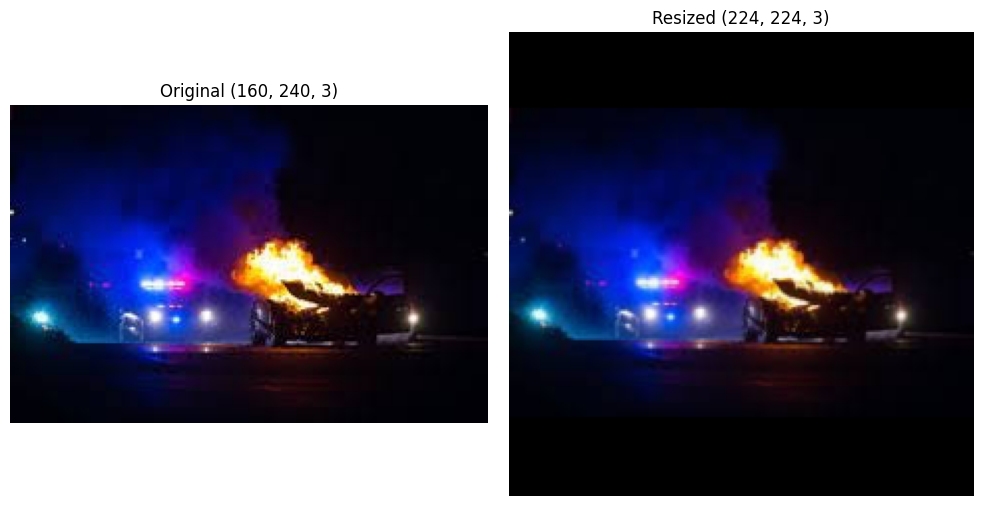

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(img_rgb)
axes[0].set_title(f"Original {img_rgb.shape}")
axes[0].axis("off")

axes[1].imshow(resized)
axes[1].set_title(f"Resized {resized.shape}")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [12]:
print("Image shape:", resized.shape)
print("Data type:", resized.dtype)

# First pixel
print("Pixel [0,0]:", resized[0, 0])

# Center pixel
print("Pixel [112,112]:", resized[112, 112])

# First 5x5 pixels (all RGB channels)
print(resized[:5, :5, :])

Image shape: (224, 224, 3)
Data type: uint8
Pixel [0,0]: [0 0 0]
Pixel [112,112]: [232 166  52]
[[[0 0 0]
  [0 0 0]
  [0 0 0]
  [0 0 0]
  [0 0 0]]

 [[0 0 0]
  [0 0 0]
  [0 0 0]
  [0 0 0]
  [0 0 0]]

 [[0 0 0]
  [0 0 0]
  [0 0 0]
  [0 0 0]
  [0 0 0]]

 [[0 0 0]
  [0 0 0]
  [0 0 0]
  [0 0 0]
  [0 0 0]]

 [[0 0 0]
  [0 0 0]
  [0 0 0]
  [0 0 0]
  [0 0 0]]]


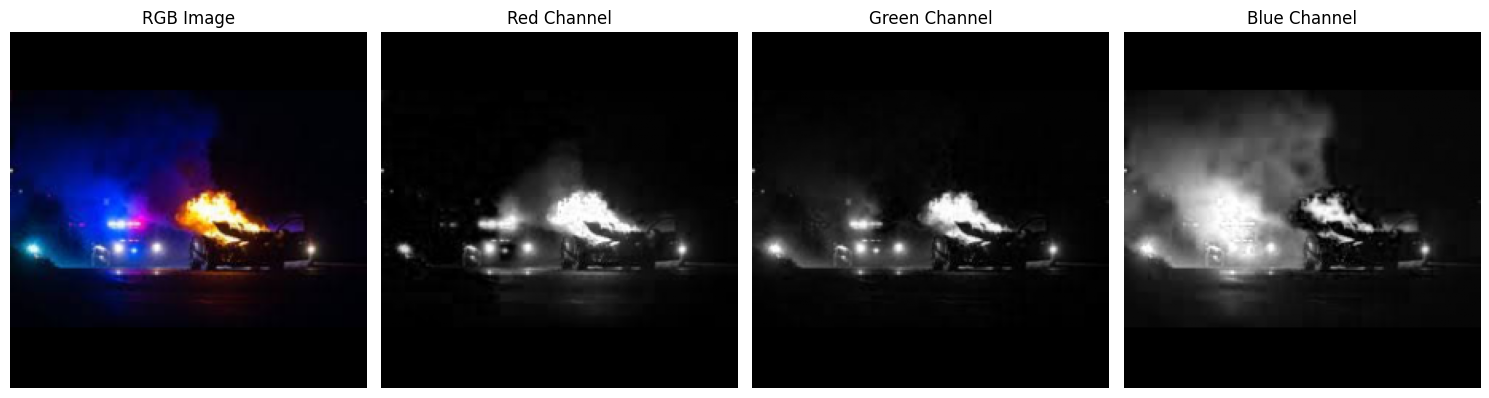

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4))

axes[0].imshow(resized)
axes[0].set_title("RGB Image")

for i, channel in enumerate(["Red", "Green", "Blue"]):
    axes[i+1].imshow(resized[:, :, i], cmap="gray", vmin=0, vmax=255)
    axes[i+1].set_title(f"{channel} Channel")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

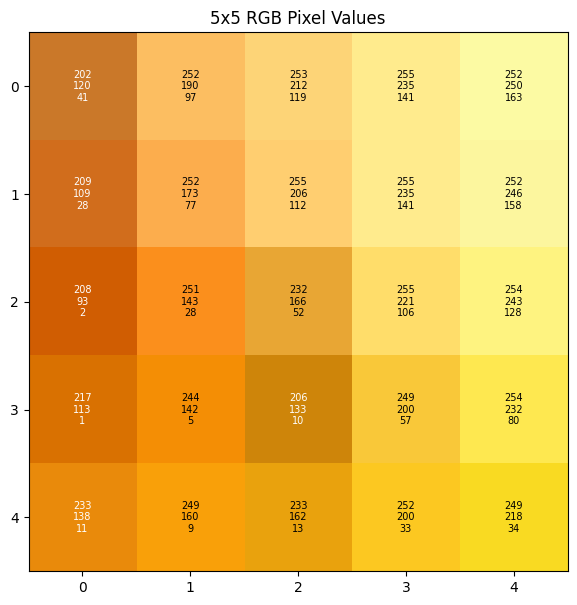

In [14]:
# Extract a 5x5 region from the center
patch = resized[110:115, 110:115]

fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(patch)

for i in range(5):
    for j in range(5):
        r, g, b = patch[i, j]
        ax.text(
            j, i,
            f"{r}\n{g}\n{b}",
            ha="center",
            va="center",
            fontsize=7,
            color="white" if np.mean(patch[i, j]) < 128 else "black"
        )

ax.set_xticks(range(5))
ax.set_yticks(range(5))
ax.set_title("5x5 RGB Pixel Values")
plt.show()

In [15]:
np.save(output_dir / "fire_resized.npy", resized)

# Reload later
loaded = np.load(output_dir / "fire_resized.npy")

print("Loaded shape:", loaded.shape)
print("Same values:", np.array_equal(resized, loaded))

Loaded shape: (224, 224, 3)
Same values: True


In [16]:
output_dir = Path("../outputs/resized_images")

total_saved = 0

for cls in classes:

    # Create a separate folder for each class
    class_output_dir = output_dir / cls
    class_output_dir.mkdir(parents=True, exist_ok=True)

    for image_path in image_paths[cls]:

        # Read original JPG
        img = cv2.imread(str(image_path))

        if img is None:
            print(f"Unable to read: {image_path}")
            continue

        # Convert BGR to RGB
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        # Resize to 224x224
        resized = resize_with_padding(img_rgb, (224, 224))

        # Save as PNG with a unique filename
        relative_path = image_path.relative_to(DATA_DIR / cls)
        safe_name = "__".join(relative_path.with_suffix("").parts)
        save_path = class_output_dir / f"{safe_name}.png"

        cv2.imwrite(
            str(save_path),
            cv2.cvtColor(resized, cv2.COLOR_RGB2BGR)
        )

        total_saved += 1

    print(f"Completed: {cls}")

print(f"\nTotal images saved: {total_saved}")

Completed: Fire
Completed: Smoke
Completed: Neutral

Total images saved: 2700


In [17]:
for cls in classes:
    folder = output_dir / cls
    count = len(list(folder.glob("*.png")))
    print(f"{cls}: {count} resized images")

Fire: 900 resized images
Smoke: 900 resized images
Neutral: 900 resized images


In [34]:
# without the black pixels (Do we need black pixels or get a distorted image like this ?)

In [20]:
def resize_image(img, target_size=(224, 224)):
    return cv2.resize(
        img,
        target_size,
        interpolation=cv2.INTER_AREA
    )

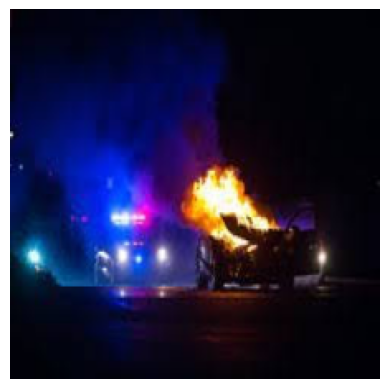

In [21]:
img = cv2.imread(str(image_paths["Fire"][0]))
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

resized = resize_image(img_rgb)

plt.imshow(resized)
plt.axis("off")
plt.show()